In [ ]:
# Run from the notebooks/ folder; data files live in ../data/ (not published, see data/README.md)
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# =========================
# GLOBAL STYLE
# =========================

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 17,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
})

# Màu dùng xuyên suốt các chart
MAIN_COLOR = "#4472C4"
HIGHLIGHT_COLOR = "#C00000"
TEXT_COLOR = "#222222"
GRID_COLOR = "#D9D9D9"


def add_bar_labels(ax, bars, decimals=1):
    """
    Hiển thị % trên đầu mỗi cột
    """
    max_value = max([bar.get_height() for bar in bars])

    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + max_value * 0.025,
            f"{height:.{decimals}f}%",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color=TEXT_COLOR
        )


def format_chart(ax, title, subtitle=None):
    """
    Format chung cho tất cả biểu đồ
    """

    ax.set_title(
        title,
        loc="left",
        pad=20,
        color=TEXT_COLOR
    )

    if subtitle:
        ax.text(
            0,
            1.01,
            subtitle,
            transform=ax.transAxes,
            fontsize=10.5,
            color="#666666",
            va="bottom"
        )

    # Horizontal grid
    ax.yaxis.grid(
        True,
        linestyle="-",
        linewidth=0.7,
        color=GRID_COLOR,
        alpha=0.7
    )

    ax.set_axisbelow(True)

    # Remove unnecessary axis
    ax.tick_params(
        axis="both",
        length=0,
        colors="#555555"
    )

    # Percentage axis
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda y, _: f"{y:.0f}%")
    )

    # Không để label sát đỉnh
    ymax = ax.get_ylim()[1]
    ax.set_ylim(0, ymax * 1.15)

    plt.tight_layout()

In [ ]:
# Load data
df = pd.read_csv('../data/Tima_clean.csv')
# Kiểm tra dữ liệu
print(df.shape)
print(df.columns.tolist())

# Tạo biến target: 1 = Nợ Xấu, 0 = Không Nợ Xấu
df["IsBadDebt"] = (df["Trạng thái"] == "Nợ Xấu").astype(int)

# Tỷ lệ nợ xấu tổng thể
default_rate = df["IsBadDebt"].mean()

print(f"Tổng số hồ sơ: {len(df):,}")
print(f"Số hồ sơ nợ xấu: {df['IsBadDebt'].sum():,}")
print(f"Tỷ lệ nợ xấu: {default_rate:.2%}")

(2383, 46)
['STT', 'application_date', 'TS_CREDIT_SCORE_V2', 'Số điện thoại khách hàng', 'FromDate', 'ID', 'LoanID', 'Số tiền đăng ký vay ban đầu', 'Tiền giải ngân', 'Tiền gốc còn lại', 'ToDate', 'Trạng thái', 'FullName', 'CardNumber', 'Gender', 'Birthday', 'CityName', 'DistrictName', 'WardName', 'Hình thức cư trú', 'Thời gian đã sống', 'Street', 'CityNameHouseHold', 'DistrictNameHouseHold', 'WardNameHouseHold', 'JobName', 'NameCompany', 'AddressCompany', 'CityCompany', 'DistrictNameCompany', 'Salary', 'ReceiveYourIncomeSalary', 'DescriptionPositionJob', 'RelativeFamilyName', 'FullNameFamily', 'ProductCreditName', 'InterestPaymentType', 'LongestOverdue', 'CreditInfo', 'Name', 'Address', 'CheckTime', 'Brieft', 'NumberOfLoans', 'HasBadDebt', 'HasLatePayment']
Tổng số hồ sơ: 2,383
Số hồ sơ nợ xấu: 206
Tỷ lệ nợ xấu: 8.64%


Finding 1 - Credit Score càng thấp → Default Rate càng cao

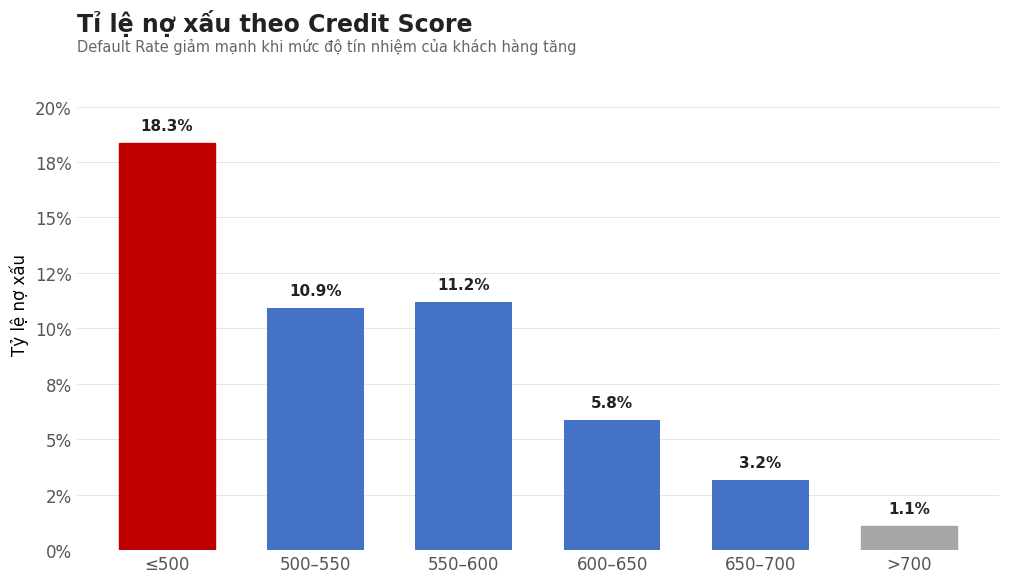

In [ ]:
import numpy as np
# =========================
# 1. BAD DEBT RATE BY CREDIT SCORE
# =========================

credit_order = [
    "≤500",
    "500–550",
    "550–600",
    "600–650",
    "650–700",
    ">700"
]

# Create bins for credit score
bins = [-np.inf, 500, 550, 600, 650, 700, np.inf]

df["CreditScore_Group"] = pd.cut(
    df["TS_CREDIT_SCORE_V2"],
    bins=bins,
    labels=credit_order,
    right=False # Set to False to make bins like (500, 550] instead of [500, 550)
)

credit_rate = (
    df.groupby("CreditScore_Group", observed=True)["IsBadDebt"]
      .mean()
      .reindex(credit_order)
      .mul(100)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    credit_rate.index,
    credit_rate.values,
    width=0.65,
    color=MAIN_COLOR
)

# Highlight nhóm rủi ro cao nhất
max_idx = credit_rate.values.argmax()

bars[max_idx].set_color(HIGHLIGHT_COLOR)

add_bar_labels(ax, bars)

format_chart(
    ax,
    "Tỉ lệ nợ xấu theo Credit Score",
    "Default Rate giảm mạnh khi mức độ tín nhiệm của khách hàng tăng"
)

ax.set_xlabel("")
ax.set_ylabel("Tỷ lệ nợ xấu")

bars[0].set_color(HIGHLIGHT_COLOR)
bars[-1].set_color("#A6A6A6")

plt.show()

Finding 2 — Khách hàng từng có Bad Debt có rủi ro cao hơn



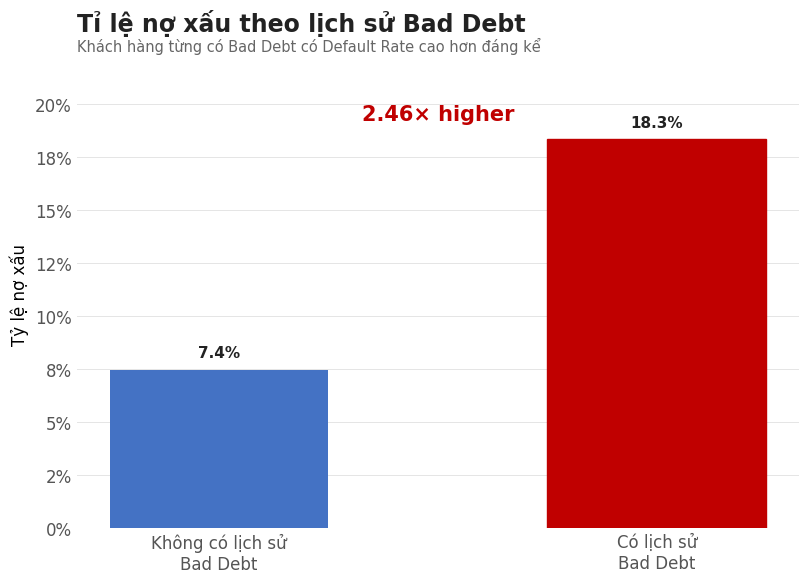

In [ ]:
# =========================
# 2. BAD DEBT HISTORY
# =========================

history_rate = (
    df.groupby("HasBadDebt")["IsBadDebt"]
      .mean()
      .mul(100)
)

history_labels = [
    "Không có lịch sử\nBad Debt",
    "Có lịch sử\nBad Debt"
]

values = [
    history_rate.get(0, np.nan),
    history_rate.get(1, np.nan)
]

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(
    history_labels,
    values,
    width=0.5,
    color=MAIN_COLOR
)

# Highlight nhóm từng có Bad Debt
bars[1].set_color(HIGHLIGHT_COLOR)

add_bar_labels(ax, bars)

format_chart(
    ax,
    "Tỉ lệ nợ xấu theo lịch sử Bad Debt",
    "Khách hàng từng có Bad Debt có Default Rate cao hơn đáng kể"
)

ratio = values[1] / values[0]

ax.text(
    0.5,
    max(values) * 1.05,
    f"{ratio:.2f}× higher",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color=HIGHLIGHT_COLOR
)

ax.set_xlabel("")
ax.set_ylabel("Tỷ lệ nợ xấu")

plt.show()

Finding 3 — Quá hạn càng dài → Default Rate càng cao

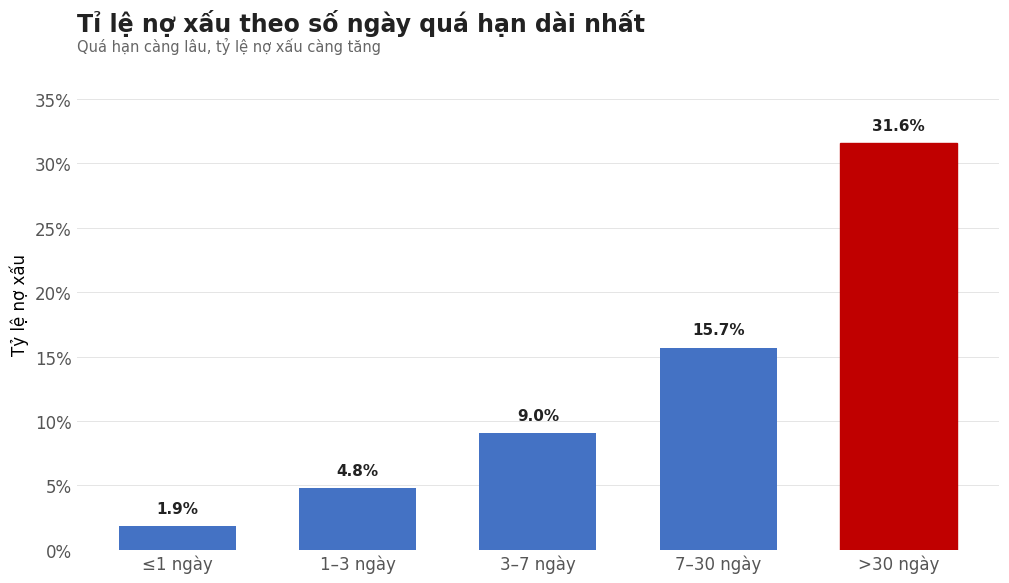

Correlation = 0.199


In [ ]:
# =========================
# 3. BAD DEBT RATE BY LONGEST OVERDUE
# =========================

overdue_order = [
    "≤1 ngày",
    "1–3 ngày",
    "3–7 ngày",
    "7–30 ngày",
    ">30 ngày"
]

# Create bins for LongestOverdue
bins = [-np.inf, 1, 3, 7, 30, np.inf]

df["Overdue_Group"] = pd.cut(
    df["LongestOverdue"],
    bins=bins,
    labels=overdue_order,
    right=False
)

overdue_rate = (
    df.groupby("Overdue_Group", observed=True)["IsBadDebt"]
      .mean()
      .reindex(overdue_order)
      .mul(100)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    overdue_rate.index,
    overdue_rate.values,
    width=0.65,
    color=MAIN_COLOR
)

# Highlight nhóm >30 ngày
bars[-1].set_color(HIGHLIGHT_COLOR)

add_bar_labels(ax, bars)

format_chart(
    ax,
    "Tỉ lệ nợ xấu theo số ngày quá hạn dài nhất",
    "Quá hạn càng lâu, tỷ lệ nợ xấu càng tăng"
)

ax.set_xlabel("")
ax.set_ylabel("Tỷ lệ nợ xấu")

plt.show()

#Correlation
r = df["LongestOverdue"].corr(df["IsBadDebt"])

print(f"Correlation = {r:.3f}")

Finding 4 — Thu nhập và Nợ xấu

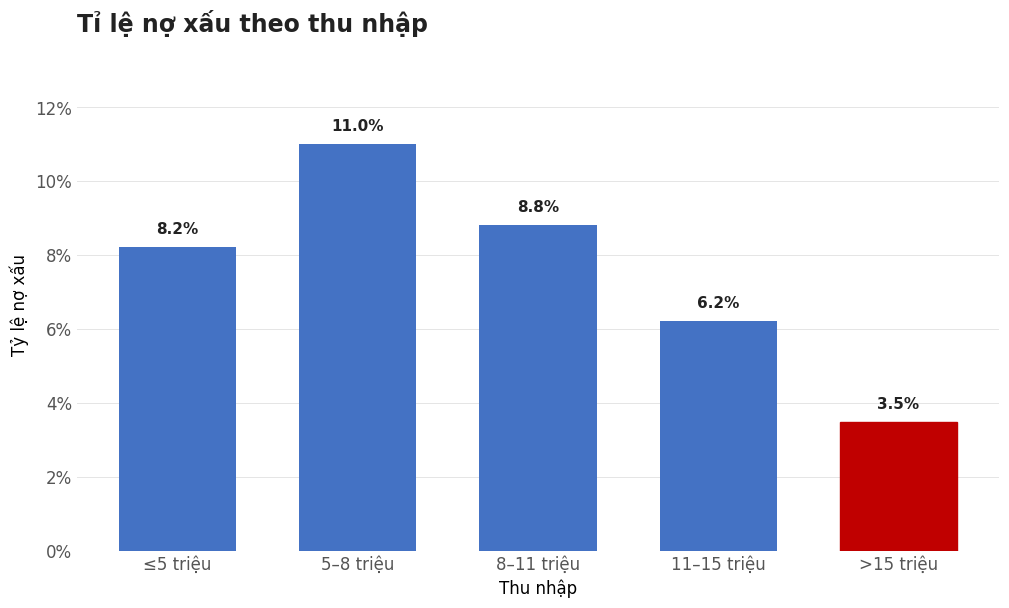

Correlation = -0.051


In [ ]:
# =========================
# 4. BAD DEBT RATE BY SALARY
# =========================

#Tạo nhóm thu nhập
bins = [-np.inf, 5_000_000, 8_000_000, 11_000_000, 15_000_000, np.inf]

labels = [
    "≤5 triệu",
    "5–8 triệu",
    "8–11 triệu",
    "11–15 triệu",
    ">15 triệu"
]

df["Salary_Group"] = pd.cut(
    df["Salary"],
    bins=bins,
    labels=labels
)

salary_order = [
    "≤5 triệu",
    "5–8 triệu",
    "8–11 triệu",
    "11–15 triệu",
    ">15 triệu"
]

salary_rate = (
    df.groupby("Salary_Group", observed=True)["IsBadDebt"]
      .mean()
      .reindex(salary_order)
      .mul(100)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    salary_rate.index,
    salary_rate.values,
    width=0.65,
    color=MAIN_COLOR
)

# Highlight nhóm thu nhập cao
bars[-1].set_color(HIGHLIGHT_COLOR)

add_bar_labels(ax, bars)

format_chart(
    ax,
    "Tỉ lệ nợ xấu theo thu nhập"
)

ax.set_xlabel("Thu nhập")
ax.set_ylabel("Tỷ lệ nợ xấu")

plt.show()

#Correlation
r = df["Salary"].corr(df["IsBadDebt"])

print(f"Correlation = {r:.3f}")

Finding 5 — Kiểm tra giả thuyết “Vay càng nhiều → Nợ xấu càng cao”

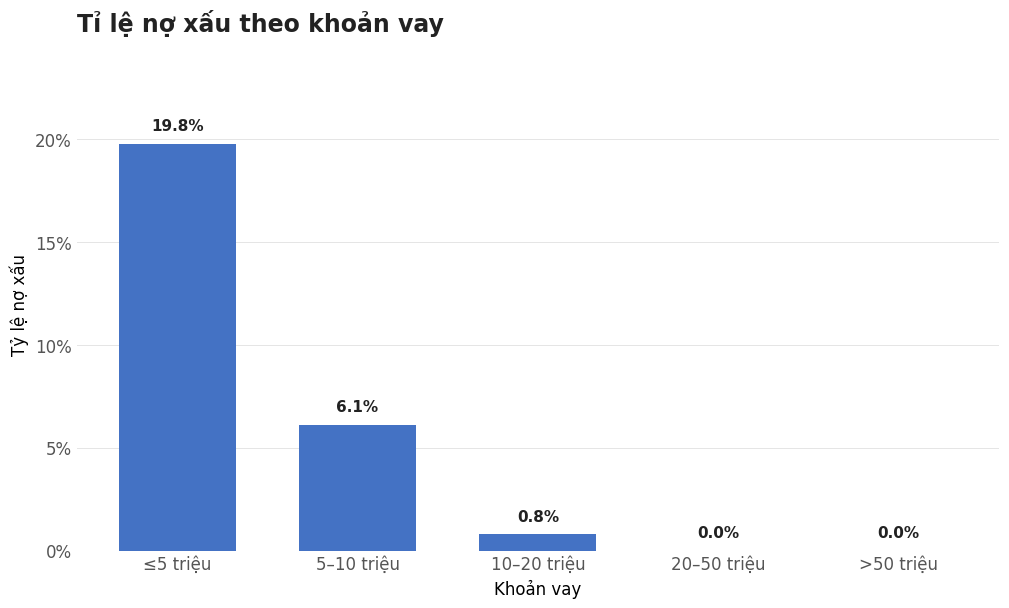

Correlation = -0.046


In [ ]:
# =========================
# 5. BAD DEBT RATE BY LOAN AMOUNT
# =========================

#Tạo nhóm khoản vay
loan_col = "Số tiền đăng ký vay ban đầu" # Corrected spelling
bins = [
    -np.inf,
    5_000_000,
    10_000_000,
    20_000_000,
    50_000_000,
    np.inf
]

labels = [
    "≤5 triệu",
    "5–10 triệu",
    "10–20 triệu",
    "20–50 triệu",
    ">50 triệu"
]

df["Loan_Group"] = pd.cut(
    df[loan_col],
    bins=bins,
    labels=labels
)

loan_order = [
    "≤5 triệu",
    "5–10 triệu",
    "10–20 triệu",
    "20–50 triệu",
    ">50 triệu"
]

loan_rate = (
    df.groupby("Loan_Group", observed=True)["IsBadDebt"]
      .mean()
      .reindex(loan_order)
      .mul(100)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    loan_rate.index,
    loan_rate.values,
    width=0.65,
    color=MAIN_COLOR
)

add_bar_labels(ax, bars)

format_chart(
    ax,
    "Tỉ lệ nợ xấu theo khoản vay",
)

ax.set_xlabel("Khoản vay")
ax.set_ylabel("Tỷ lệ nợ xấu")

plt.show()

#Correlation
r = df[loan_col].corr(df["IsBadDebt"])

print(f"Correlation = {r:.3f}")

Finding 6 — Nghề nghiệp → Nợ xấu

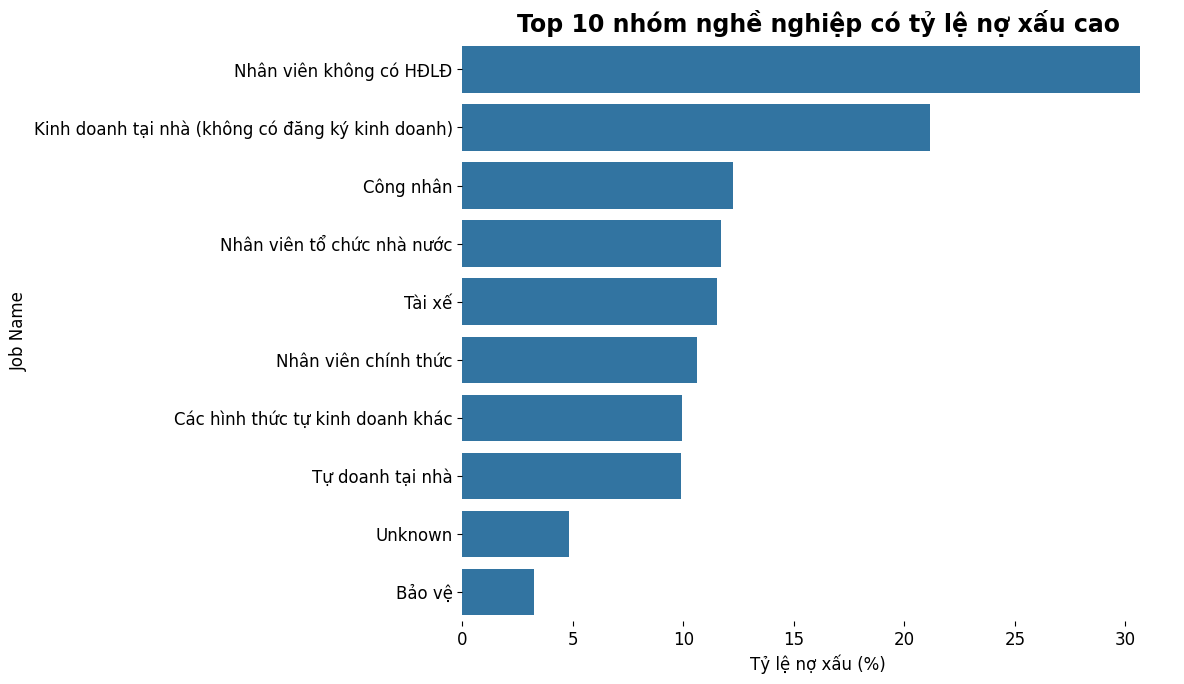

Default Rate toàn bộ dataset: 8.64%


,JobName,Total,BadDebt,Default_Rate,Lift_vs_Baseline
29,Nhân viên không có HĐLĐ,75,23,30.666667,3.547508
18,Kinh doanh tại nhà (không có đăng ký kinh doanh),52,11,21.153846,2.447069
6,Công nhân,49,6,12.244898,1.416485
30,Nhân viên tổ chức nhà nước,77,9,11.688312,1.352099
37,Tài xế,52,6,11.538462,1.334765
28,Nhân viên chính thức,1083,115,10.618652,1.228362
5,Các hình thức tự kinh doanh khác,131,13,9.923664,1.147966
43,Tự doanh tại nhà,81,8,9.876543,1.142515
44,Unknown,248,12,4.838710,0.559740
1,Bảo vệ,31,1,3.225806,0.373160


In [ ]:
#Tính theo Job Name
job_analysis = (
    df.groupby("JobName")
      .agg(
          Total=("IsBadDebt", "size"),
          BadDebt=("IsBadDebt", "sum"),
          Default_Rate=("IsBadDebt", "mean")
      )
      .reset_index()
)
#Chỉ lấy nhóm có đủ sample
job_analysis_filtered = (
    job_analysis[
        job_analysis["Total"] >= 30
    ]
    .sort_values("Default_Rate", ascending=False)
)

job_analysis_filtered["Default_Rate"] *= 100

job_analysis_filtered.head(15)
#Top nhóm rủi ro
top_jobs = job_analysis_filtered.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_jobs,
    x="Default_Rate",
    y="JobName" # Corrected from "Job Name" to "JobName"
)

plt.title("Top 10 nhóm nghề nghiệp có tỷ lệ nợ xấu cao")
plt.xlabel("Tỷ lệ nợ xấu (%)")
plt.ylabel("Job Name")

plt.tight_layout()
plt.show()
#So với baseline
baseline = df["IsBadDebt"].mean() * 100
print(f"Default Rate toàn bộ dataset: {baseline:.2f}%")

job_analysis_filtered["Lift_vs_Baseline"] = (
    job_analysis_filtered["Default_Rate"] / baseline
)
job_analysis_filtered.head(10)

In [ ]:
summary = pd.DataFrame({
    "Finding": [
        "Credit Score",
        "Has Bad Debt History",
        "Longest Overdue",
        "Salary",
        "Loan Amount"
    ],
    "Correlation": [
        df["TS_CREDIT_SCORE_V2"].corr(df["IsBadDebt"]),
        df["HasBadDebt"].corr(df["IsBadDebt"]),
        df["LongestOverdue"].corr(df["IsBadDebt"]),
        df["Salary"].corr(df["IsBadDebt"]),
        df["Số tiền đăng ký vay ban đầu"].corr(df["IsBadDebt"])
    ]
})

summary

,Finding,Correlation
0,Credit Score,-0.204468
1,Has Bad Debt History,0.121015
2,Longest Overdue,0.199284
3,Salary,-0.051105
4,Loan Amount,-0.045627


Đào sâu Job

In [ ]:
job_risk = (
    df.groupby("JobName")
      .agg(
          Total=("IsBadDebt", "size"),
          Default_Rate=("IsBadDebt", "mean"),
          Avg_CreditScore=("TS_CREDIT_SCORE_V2", "mean"),
          BadDebt_History=("HasBadDebt", "mean"),
          Avg_Overdue=("LongestOverdue", "mean"),
          Avg_Salary=("Salary", "mean")
      )
      .reset_index()
)

job_risk = job_risk[
    job_risk["Total"] >= 30
].copy()

job_risk["Default_Rate"] *= 100
job_risk["BadDebt_History"] *= 100

job_risk = job_risk.sort_values(
    "Default_Rate",
    ascending=False
)

job_risk.head(15)

,JobName,Total,Default_Rate,Avg_CreditScore,BadDebt_History,Avg_Overdue,Avg_Salary
29,Nhân viên không có HĐLĐ,75,30.666667,562.653333,16.000000,7.108108,7.417333e+06
18,Kinh doanh tại nhà (không có đăng ký kinh doanh),52,21.153846,533.384615,17.307692,10.000000,1.294231e+07
6,Công nhân,49,12.244898,608.163265,10.204082,8.595745,8.568730e+06
30,Nhân viên tổ chức nhà nước,77,11.688312,577.987013,16.883117,9.363636,8.388312e+06
37,Tài xế,52,11.538462,540.423077,9.615385,4.313725,1.060577e+07
28,Nhân viên chính thức,1083,10.618652,588.786704,11.819021,6.590994,9.182835e+06
5,Các hình thức tự kinh doanh khác,131,9.923664,580.145038,12.977099,7.000000,1.537405e+07
43,Tự doanh tại nhà,81,9.876543,569.530864,12.345679,4.772152,1.247531e+07
44,Unknown,248,4.838710,586.548387,12.096774,4.243802,4.833648e+06
1,Bảo vệ,31,3.225806,533.290323,9.677419,8.586207,7.174194e+06


Đào sâu Salary

In [ ]:
df["Salary_Group"] = pd.qcut(
    df["Salary"],
    q=4,
    duplicates="drop"
)

salary_risk = (
    df.groupby("Salary_Group", observed=True)
      .agg(
          Total=("IsBadDebt", "size"),
          Default_Rate=("IsBadDebt", "mean"),
          Avg_CreditScore=("TS_CREDIT_SCORE_V2", "mean"),
          BadDebt_History=("HasBadDebt", "mean"),
          Avg_Overdue=("LongestOverdue", "mean")
      )
      .reset_index()
)

salary_risk["Default_Rate"] *= 100
salary_risk["BadDebt_History"] *= 100

salary_risk

,Salary_Group,Total,Default_Rate,Avg_CreditScore,BadDebt_History,Avg_Overdue
0,"(-0.001, 6500000.0]",647,9.582689,574.825348,10.819165,5.785150
1,"(6500000.0, 8000000.0]",572,10.839161,585.050699,13.111888,6.440860
2,"(8000000.0, 11000000.0]",590,8.813559,592.303390,11.016949,6.077586
3,"(11000000.0, 100000000.0]",569,5.272408,608.377856,9.138840,5.736559


Tạo risk score


In [ ]:
df["Low_Credit"] = (
    df["TS_CREDIT_SCORE_V2"] <= 550
).astype(int)

df["Previous_BadDebt"] = (
    df["HasBadDebt"] == 1
).astype(int)

df["Severe_Overdue"] = (
    df["LongestOverdue"] > 30
).astype(int)

df["Risk_Flag"] = (
    df["Low_Credit"]
    + df["Previous_BadDebt"]
    + df["Severe_Overdue"]
)
risk_flag_analysis = (
    df.groupby("Risk_Flag")
      .agg(
          Total=("IsBadDebt", "size"),
          BadDebt=("IsBadDebt", "sum"),
          Default_Rate=("IsBadDebt", "mean")
      )
      .reset_index()
)

risk_flag_analysis["Default_Rate"] *= 100

risk_flag_analysis

,Risk_Flag,Total,BadDebt,Default_Rate
0,0,1471,65,4.418763
1,1,759,102,13.438735
2,2,143,34,23.776224
3,3,10,5,50.000000


Tạo bảng risk profile

In [ ]:
risk_summary = (
    df.groupby("Risk_Flag")
      .agg(
          Customers=("IsBadDebt", "size"),
          Bad_Debt=("IsBadDebt", "sum"),
          Default_Rate=("IsBadDebt", "mean"),
          Avg_Credit_Score=("TS_CREDIT_SCORE_V2", "mean"),
          Avg_Salary=("Salary", "mean"),
          Avg_Overdue=("LongestOverdue", "mean"),
          Bad_Debt_History=("HasBadDebt", "mean")
      )
      .reset_index()
)

risk_summary["Default_Rate"] *= 100
risk_summary["Bad_Debt_History"] *= 100

risk_summary

,Risk_Flag,Customers,Bad_Debt,Default_Rate,Avg_Credit_Score,Avg_Salary,Avg_Overdue,Bad_Debt_History
0,0,1471,65,4.418763,642.431679,9.618165e+06,3.765157,0.000000
1,1,759,102,13.438735,511.130435,9.140586e+06,6.369478,19.499341
2,2,143,34,23.776224,473.881119,9.552448e+06,24.056338,72.727273
3,3,10,5,50.000000,464.100000,7.350000e+06,43.500000,100.000000
